In [1]:
import pandas as pd
EV = "/home/jovyan/vault/heidelberg_lulc_2025/outputs/evaluation"
pd.set_option("display.width", 220)

ov = pd.read_csv(f"{EV}/summary_overall.csv")
pc = pd.read_csv(f"{EV}/summary_per_class.csv")

print("=== Overall test results (OA / mIoU / mean F1) ===")
t = ov.pivot_table(index=["train_res", "arch"], columns="mode", values=["OA", "mIoU"]).round(3)
print(t.to_string())

best = "segformer_train10_VV-VH-RATIO_s42"
print(f"\n=== Per-class IoU and F1 on the 10 m test set — {best} ===")
b = pc[(pc.run == best) & (pc["mode"] == "test10")][["class", "IoU", "F1", "support_px"]]
print(b.round(3).to_string(index=False))

print("\n=== Per-class IoU, all 10 m models (test10) ===")
print(pc[(pc.train_res.astype(str) == "10") & (pc["mode"] == "test10")]
      .pivot(index="class", columns="arch", values="IoU").round(3).to_string())


=== Overall test results (OA / mIoU / mean F1) ===
                            OA                        mIoU                     
mode                    test10 test40 test40_from10 test10 test40 test40_from10
train_res arch                                                                 
10        deeplabv3plus  0.810  0.562         0.813  0.407  0.138         0.407
          fpn            0.816  0.636         0.818  0.400  0.196         0.401
          segformer      0.832  0.663         0.834  0.432  0.235         0.433
          unet           0.818  0.615         0.820  0.423  0.189         0.424
40        deeplabv3plus  0.343  0.758         0.344  0.104  0.342         0.104
          fpn            0.524  0.758         0.528  0.170  0.327         0.170
          segformer      0.349  0.772         0.353  0.169  0.348         0.170
          unet           0.388  0.782         0.391  0.113  0.343         0.114

=== Per-class IoU and F1 on the 10 m test set — segformer_train10_VV

In [1]:
import numpy as np, pandas as pd
EV = "/home/jovyan/vault/heidelberg_lulc_2025/outputs/evaluation"
GROUPS = {"Water": [0], "Trees": [1], "Low vegetation": [2, 5, 3],
          "Crops": [4], "Built-up": [6], "Bare / snow": [7, 8]}

def merged_metrics(run, mode="test10"):
    cm = pd.read_csv(f"{EV}/{run}/confusion_{mode}.csv", index_col=0).values
    G = np.zeros((9, len(GROUPS)))
    for j, idx in enumerate(GROUPS.values()):
        G[idx, j] = 1
    m = G.T @ cm @ G                                   # merge rows and columns
    tp, gt, pr = np.diag(m), m.sum(1), m.sum(0)
    iou, f1 = tp / (gt + pr - tp), 2 * tp / (gt + pr)
    return tp.sum() / m.sum(), iou.mean(), f1.mean(), dict(zip(GROUPS, iou.round(3)))

rows = []
for arch in ["segformer", "unet", "deeplabv3plus", "fpn"]:
    oa, miou, mf1, per = merged_metrics(f"{arch}_train10_VV-VH-RATIO_s42")
    rows.append({"model": arch, "OA_6class": round(oa, 3), "mIoU_6class": round(miou, 3),
                 "mF1_6class": round(mf1, 3), **per})
res = pd.DataFrame(rows)
res.to_csv(f"{EV}/merged_6class_results_test10.csv", index=False)
print(res.to_string(index=False))

        model  OA_6class  mIoU_6class  mF1_6class  Water  Trees  Low vegetation  Crops  Built-up  Bare / snow
    segformer      0.836        0.596       0.716  0.669  0.788           0.332  0.730     0.844        0.215
         unet      0.822        0.581       0.702  0.663  0.770           0.302  0.711     0.840        0.203
deeplabv3plus      0.814        0.569       0.692  0.635  0.766           0.296  0.687     0.835        0.194
          fpn      0.821        0.565       0.682  0.644  0.774           0.312  0.692     0.836        0.131


In [2]:
import pandas as pd
P = "/home/jovyan/vault/heidelberg_lulc_2025"
b = pd.read_csv(f"{P}/outputs/splits/blocks_and_splits.csv")
print("Each super-block in exactly one split:", (b.groupby("superblock").split.nunique() == 1).all())
for res in ("10m", "40m"):
    blk = {s: set(pd.read_csv(f"{P}/patches/{res}/{s}_meta.csv").block_id) for s in ("train", "val", "test")}
    print(res, "| train∩test:", len(blk["train"] & blk["test"]), "| train∩val:", len(blk["train"] & blk["val"]),
          "| val∩test:", len(blk["val"] & blk["test"]))

Each super-block in exactly one split: True
10m | train∩test: 0 | train∩val: 0 | val∩test: 0
40m | train∩test: 0 | train∩val: 0 | val∩test: 0


=== 9 vs 6 classes, 10 m test set ===
                OA_9   OA_6  OA_diff  mIoU_9  mIoU_6  mIoU_diff  mF1_9  mF1_6  mF1_diff
model                                                                                  
segformer      0.832  0.836    0.004   0.432   0.596      0.164  0.537  0.716     0.178
unet           0.818  0.822    0.004   0.423   0.581      0.158  0.531  0.702     0.171
deeplabv3plus  0.810  0.814    0.004   0.407   0.569      0.162  0.509  0.692     0.183
fpn            0.816  0.821    0.005   0.400   0.565      0.165  0.496  0.682     0.186


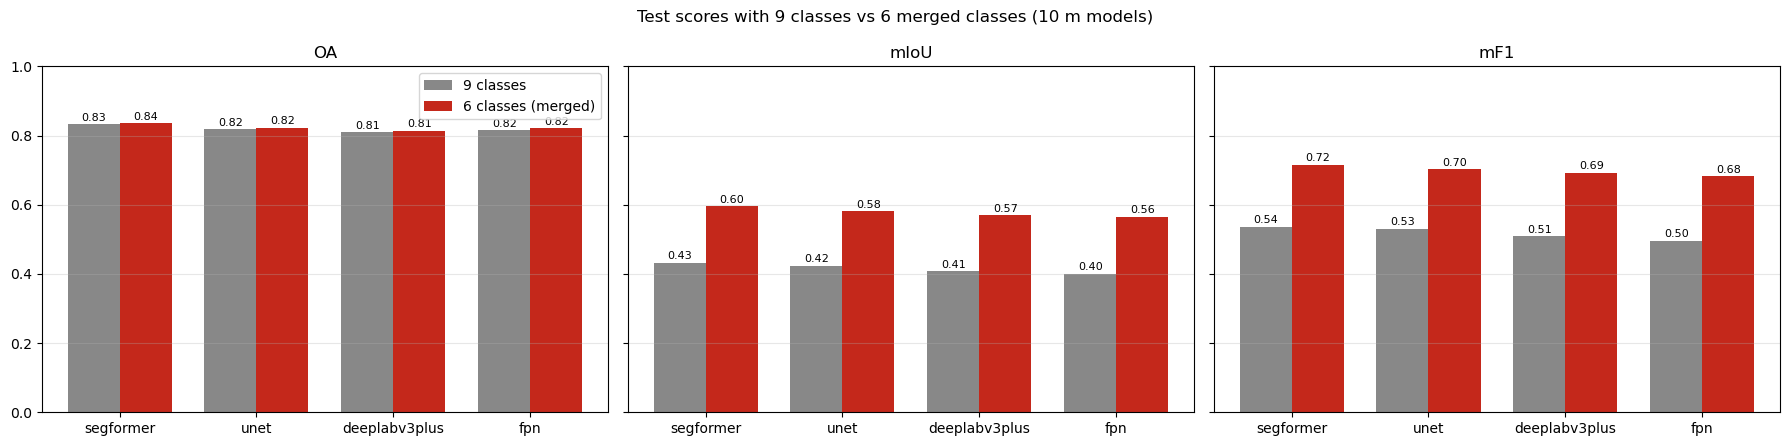

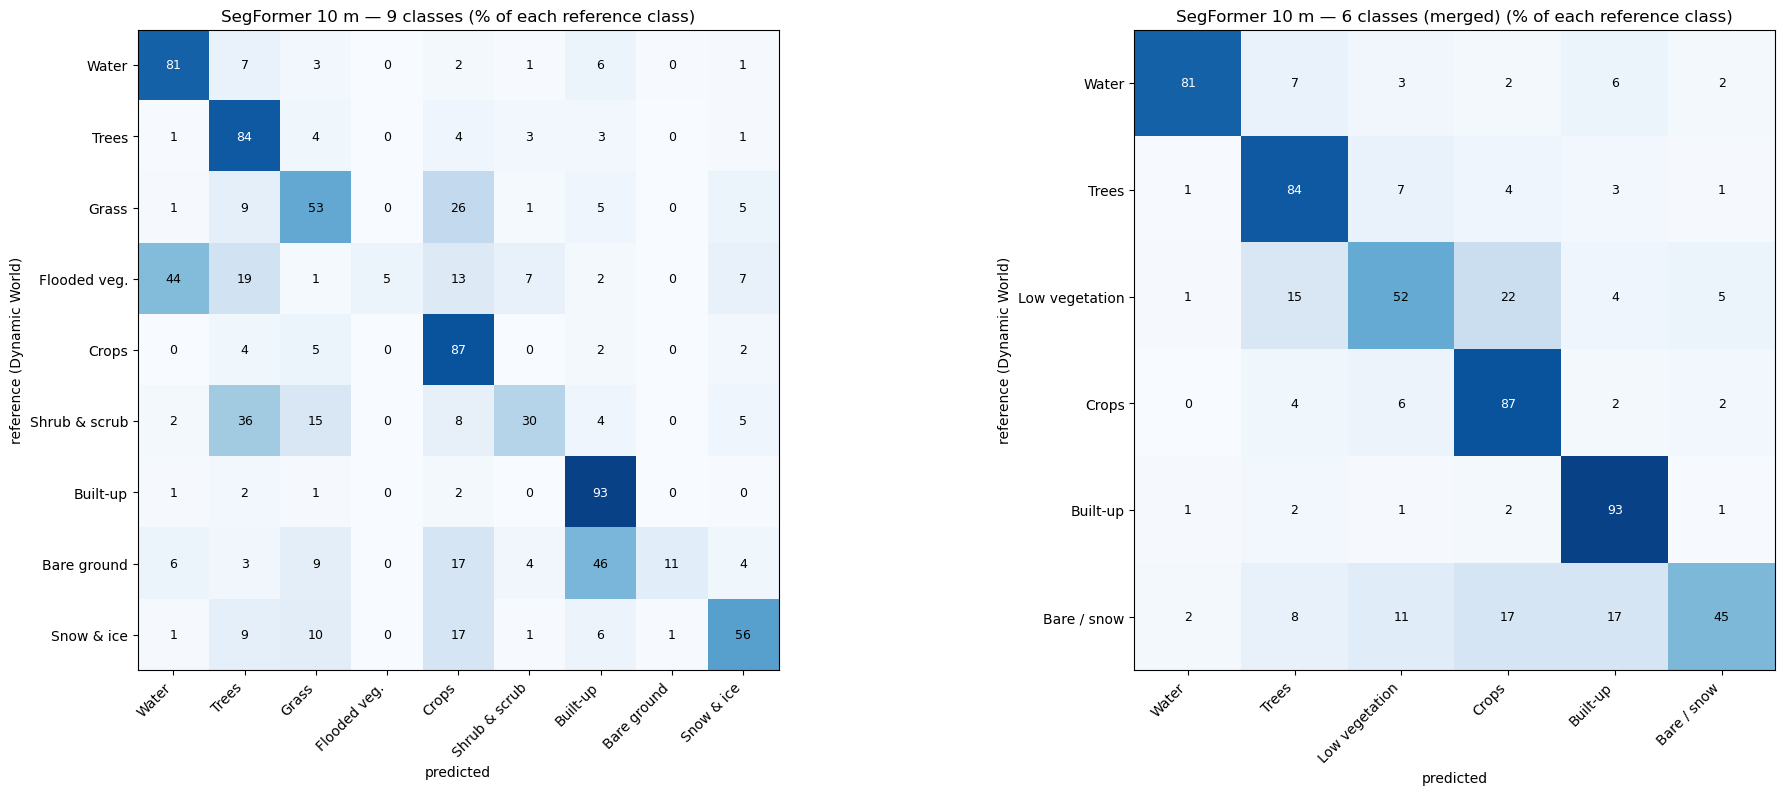

Saved: /home/jovyan/vault/heidelberg_lulc_2025/outputs/evaluation/comparison_9_vs_6_classes_test10.csv


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
P = "/home/jovyan/vault/heidelberg_lulc_2025"
EV, FIG = f"{P}/outputs/evaluation", f"{P}/outputs/figures"
C9 = ["Water", "Trees", "Grass", "Flooded veg.", "Crops", "Shrub & scrub", "Built-up", "Bare ground", "Snow & ice"]
GROUPS = {"Water": [0], "Trees": [1], "Low vegetation": [2, 5, 3], "Crops": [4], "Built-up": [6], "Bare / snow": [7, 8]}
G = np.zeros((9, len(GROUPS)))
for j, idx in enumerate(GROUPS.values()):
    G[idx, j] = 1

def scores(cm):
    tp, gt, pr = np.diag(cm), cm.sum(1), cm.sum(0)
    ok = gt > 0
    iou = tp / np.maximum(gt + pr - tp, 1); f1 = 2 * tp / np.maximum(gt + pr, 1)
    return tp.sum() / cm.sum(), iou[ok].mean(), f1[ok].mean()

rows, cms = [], {}
for arch in ["segformer", "unet", "deeplabv3plus", "fpn"]:
    cm9 = pd.read_csv(f"{EV}/{arch}_train10_VV-VH-RATIO_s42/confusion_test10.csv", index_col=0).values.astype(float)
    cm6 = G.T @ cm9 @ G
    cms[arch] = (cm9, cm6)
    (oa9, mi9, f9), (oa6, mi6, f6) = scores(cm9), scores(cm6)
    rows.append({"model": arch, "OA_9": oa9, "OA_6": oa6, "OA_diff": oa6 - oa9,
                 "mIoU_9": mi9, "mIoU_6": mi6, "mIoU_diff": mi6 - mi9,
                 "mF1_9": f9, "mF1_6": f6, "mF1_diff": f6 - f9})
t = pd.DataFrame(rows).set_index("model").round(3)
t.to_csv(f"{EV}/comparison_9_vs_6_classes_test10.csv")
print("=== 9 vs 6 classes, 10 m test set ===")
print(t.to_string())

# --- bar chart ---
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
x = np.arange(len(t)); w = 0.38
for ax, m in zip(axs, ["OA", "mIoU", "mF1"]):
    ax.bar(x - w/2, t[f"{m}_9"], w, label="9 classes", color="#888888")
    ax.bar(x + w/2, t[f"{m}_6"], w, label="6 classes (merged)", color="#c4281b")
    for i, (a, b) in enumerate(zip(t[f"{m}_9"], t[f"{m}_6"])):
        ax.text(i - w/2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8)
        ax.text(i + w/2, b + 0.01, f"{b:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_title(m); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=0.3)
axs[0].legend()
fig.suptitle("Test scores with 9 classes vs 6 merged classes (10 m models)")
plt.tight_layout(); plt.savefig(f"{FIG}/comparison_9_vs_6_classes.png", dpi=150); plt.show()

# --- confusion matrices, SegFormer ---
cm9, cm6 = cms["segformer"]
fig, axs = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [9, 6]})
for ax, cm, names, title in [(axs[0], cm9, C9, "9 classes"), (axs[1], cm6, list(GROUPS), "6 classes (merged)")]:
    pctm = 100 * cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(pctm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f"{pctm[i, j]:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if pctm[i, j] > 60 else "black")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel("predicted"); ax.set_ylabel("reference (Dynamic World)")
    ax.set_title(f"SegFormer 10 m — {title} (% of each reference class)")
plt.tight_layout(); plt.savefig(f"{FIG}/confusion_9_vs_6_segformer.png", dpi=150); plt.show()
print("Saved:", f"{EV}/comparison_9_vs_6_classes_test10.csv")

In [1]:
import pandas as pd
EV = "/home/jovyan/vault/heidelberg_lulc_2025/outputs/evaluation"
run = "segformer_train10_VV-VH-RATIO_s42"
cm = pd.read_csv(f"{EV}/{run}/confusion_test10.csv", index_col=0)
short = ["Water", "Trees", "Grass", "FloodVeg", "Crops", "Shrub", "Built-up", "Bare", "Snow"]
cm.index, cm.columns = short, short
cm.index.name, cm.columns.name = "reference ↓ / predicted →", None

pd.set_option("display.width", 250)
print("=== Pixel counts ===")
print(cm.to_string())

row_pct = (100 * cm.div(cm.sum(axis=1), axis=0)).round(1)      # recall view: where each reference class went
col_pct = (100 * cm.div(cm.sum(axis=0), axis=1)).round(1)      # precision view: what each prediction really was
print("\n=== Row % (each row sums to 100; diagonal = recall / producer's accuracy) ===")
print(row_pct.to_string())
print("\n=== Column % (each column sums to 100; diagonal = precision / user's accuracy) ===")
print(col_pct.to_string())

out = f"{EV}/{run}"
cm.to_csv(f"{out}/confusion_test10_counts_named.csv")
row_pct.to_csv(f"{out}/confusion_test10_row_percent.csv")
col_pct.to_csv(f"{out}/confusion_test10_col_percent.csv")
print("\nSaved to:", out)

=== Pixel counts ===
                            Water    Trees   Grass  FloodVeg    Crops   Shrub  Built-up   Bare    Snow
reference ↓ / predicted →                                                                             
Water                      662867    54796   21976       103    13701    4180     48598   4051    8855
Trees                       79962  8810863  376463       382   442647  320696    303500   1184  110495
Grass                       13797   141712  830139       258   413332   22723     71778   1549   85189
FloodVeg                     1398      618      47       163      417     234        70      0     236
Crops                        2296   202844  310103         0  4930783    6980    105406   3815  133540
Shrub                        7830   163922   67564         2    35344  135711     19223   1499   20371
Built-up                    57626   143518   60144         7    94807    5974   5492420  21182   23674
Bare                         6211     3241    9738  